In [1]:
!git clone --depth 1 https://github.com/hiyouga/LLaMA-Factory.git
%cd LLaMA-Factory

!pip install -e .[torch,metrics] -q

!pip install bitsandbytes peft accelerate datasets huggingface_hub trl -q

Cloning into 'LLaMA-Factory'...
remote: Enumerating objects: 740, done.
remote: Counting objects: 100% (740/740), done.
remote: Compressing objects: 100% (584/584), done.
remote: Total 740 (delta 154), reused 475 (delta 101), pack-reused 0 (from 0)
Receiving objects: 100% (740/740), 5.52 MiB | 10.97 MiB/s, done.
Resolving deltas: 100% (154/154), done.
/content/LLaMA-Factory
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 375.8/375.8 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40

In [2]:
from huggingface_hub import login
from google.colab import userdata

hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)

In [3]:
import json

dataset_info_path = "data/dataset_info.json"

with open(dataset_info_path, "r") as f:
    dataset_info = json.load(f)

In [4]:
# 1. Financial QA Dataset (from Hugging Face: llamafactory/fiqa)
dataset_info["financial_qa"] = {
    "hf_hub_url": "llamafactory/fiqa",
    "columns": {
        "prompt": "instruction",
        "query": "input",
        "response": "output"
    }
}

In [5]:
# 2. Python Code Execution Dataset (from Hugging Face: flytech/python-codes-25k)
dataset_info["python_code"] = {
    "hf_hub_url": "flytech/python-codes-25k",
    "columns": {
        "prompt": "instruction",
        "query": "input",
        "response": "output"
    }
}

In [6]:
# 3. Preference Dataset for DPO/RLHF (from Hugging Face: argilla/ultrafeedback-binarized-preferences-cleaned)
dataset_info["ultrafeedback_preference"] = {
    "hf_hub_url": "argilla/ultrafeedback-binarized-preferences-cleaned",
    "ranking": True,
    "columns": {
        "prompt": "instruction",
        "chosen": "chosen",
        "rejected": "rejected"
    }
}

In [7]:
with open(dataset_info_path, "w") as f:
    json.dump(dataset_info, f, indent=2)

print("Hugging Face datasets successfully registered in dataset_info.json")

Hugging Face datasets successfully registered in dataset_info.json


# Phase 1 — Domain-Specific Supervised Fine-Tuning (SFT)
4-bit QLoRA training on financial_qa

In [9]:
import yaml

sft_config = {
    "stage": "sft",
    "do_train": True,
    "model_name_or_path": "Qwen/Qwen2.5-1.5B-Instruct",
    "dataset": "financial_qa,python_code",
    "max_samples": 1000,
    "template": "qwen",
    "finetuning_type": "lora",
    "lora_target": "all",
    "output_dir": "saves/Qwen2.5-1.5B/lora/sft",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 4,
    "lr_scheduler_type": "cosine",
    "logging_steps": 10,
    "save_steps": 100,
    "max_steps": 120,
    "learning_rate": 2e-4,
    "quantization_bit": 4,
    "fp16": True,
}

with open("sft_config.yaml", "w") as f:
    yaml.dump(sft_config, f)

!llamafactory-cli train sft_config.yaml

/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[WARNING|2026-09-27 05:30:39] llamafactory.hparams.parser:149 >> We recommend enable `upcast_layernorm` in quantized training.
[INFO|2026-09-27 05:30:39] llamafactory.hparams.parser:651 >> Process rank: 0, world size: 1, device: cuda:0, distributed training: False, compute dtype: torch.float16
[INFO|configuration_utils.py:780] 2026-09-27 05:30:39,445 >> loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json
[INFO|configuration_utils.py:856] 2026-09-27 05:30:39,452 >> Model config Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],


# Phase 2 — Preference Alignment (DPO)
Direct Preference Optimization using the Hugging Face ultrafeedback_preference

In [13]:
import json

dataset_info_path = "data/dataset_info.json"

with open(dataset_info_path, "r") as f:
    dataset_info = json.load(f)

# Register a fully compatible pairwise DPO dataset
dataset_info["dpo_pairs"] = {
    "hf_hub_url": "argilla/distilabel-intel-orca-dpo-pairs",
    "ranking": True,
    "columns": {
        "prompt": "input",
        "chosen": "chosen",
        "rejected": "rejected"
    }
}

with open(dataset_info_path, "w") as f:
    json.dump(dataset_info, f, indent=2)

print("Updated dataset_info.json with compatible DPO pairs dataset")

Updated dataset_info.json with compatible DPO pairs dataset


In [14]:
import yaml

dpo_config = {
    "stage": "dpo",
    "do_train": True,
    "model_name_or_path": "Qwen/Qwen2.5-1.5B-Instruct",
    "adapter_name_or_path": "saves/Qwen2.5-1.5B/lora/sft",
    "dataset": "dpo_pairs",
    "max_samples": 500,
    "template": "qwen",
    "finetuning_type": "lora",
    "lora_target": "all",
    "output_dir": "saves/Qwen2.5-1.5B/lora/dpo",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "lr_scheduler_type": "cosine",
    "logging_steps": 5,
    "save_steps": 50,
    "max_steps": 60,
    "learning_rate": 5e-6,
    "quantization_bit": 4,
    "fp16": True,
}

with open("dpo_config.yaml", "w") as f:
    yaml.dump(dpo_config, f)

In [15]:
!llamafactory-cli train dpo_config.yaml

/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[WARNING|2026-09-27 05:44:15] llamafactory.hparams.parser:149 >> We recommend enable `upcast_layernorm` in quantized training.
[INFO|2026-09-27 05:44:15] llamafactory.hparams.parser:651 >> Process rank: 0, world size: 1, device: cuda:0, distributed training: False, compute dtype: torch.float16
[INFO|configuration_utils.py:780] 2026-09-27 05:44:15,755 >> loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json
[INFO|configuration_utils.py:856] 2026-09-27 05:44:15,760 >> Model config Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],


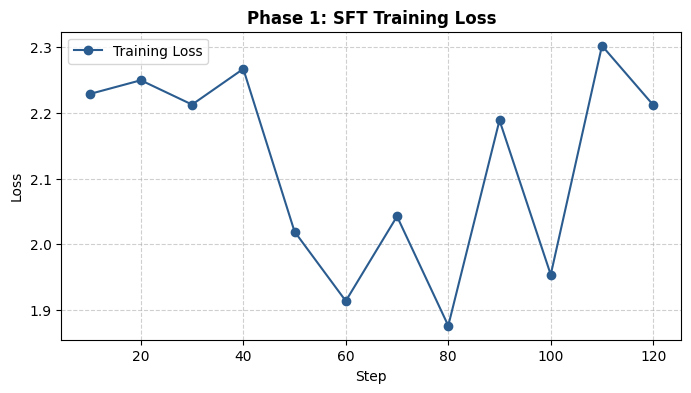

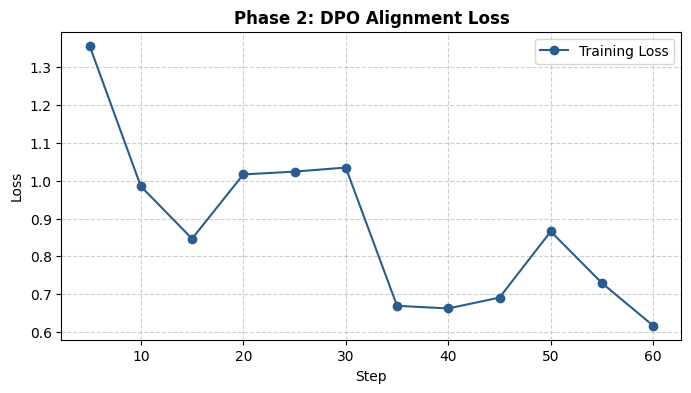

In [17]:
import json
import matplotlib.pyplot as plt

def plot_training_loss(trainer_state_path, title):
    with open(trainer_state_path, "r") as f:
        data = json.load(f)

    steps = []
    losses = []
    for log in data.get("log_history", []):
        if "loss" in log:
            steps.append(log["step"])
            losses.append(log["loss"])

    plt.figure(figsize=(8, 4))
    plt.plot(steps, losses, marker='o', color='#2b5c8f', label='Training Loss')
    plt.title(title, fontsize=12, fontweight='bold')
    plt.xlabel('Step')
    plt.ylabel('Loss')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

# Plot Phase 1 SFT Loss
plot_training_loss("saves/Qwen2.5-1.5B/lora/sft/trainer_state.json", "Phase 1: SFT Training Loss")

# Plot Phase 2 DPO Alignment Loss
plot_training_loss("saves/Qwen2.5-1.5B/lora/dpo/trainer_state.json", "Phase 2: DPO Alignment Loss")

In [18]:
import yaml

export_config = {
    "model_name_or_path": "Qwen/Qwen2.5-1.5B-Instruct",
    "adapter_name_or_path": "saves/Qwen2.5-1.5B/lora/dpo",
    "template": "qwen",
    "finetuning_type": "lora",
    "export_dir": "merged_models/Qwen2.5-1.5B-Financial-Code-Engine",
    "export_size": 2,
    "export_device": "cpu", # Merges on CPU RAM to avoid CUDA OOM
}

with open("export_config.yaml", "w") as f:
    yaml.dump(export_config, f)

# Execute Export & Weight Fusing
!llamafactory-cli export export_config.yaml

/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[INFO|configuration_utils.py:780] 2026-09-27 05:57:54,040 >> loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json
[INFO|configuration_utils.py:856] 2026-09-27 05:57:54,045 >> Model config Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "dtype": "bfloat16",
  "eos_token_id": 151645,
  "hidden_act": "silu",
  "hidden_size": 1536,
  "initializer_range": 0.02,
  "intermediate_size": 8960,
  "layer_types": [
    "full_attention",
    "full_attention",
    "full_attention",
  

# Upload Model & Tokenizer to Hugging Face Hub

In [19]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import login
from google.colab import userdata

hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)

hf_repo_id = "ahmadnawaz21/Qwen2.5-1.5B-Financial-Code-Engine"
export_dir = "merged_models/Qwen2.5-1.5B-Financial-Code-Engine"

print("Loading merged model for upload...")
model = AutoModelForCausalLM.from_pretrained(export_dir, torch_dtype="auto")
tokenizer = AutoTokenizer.from_pretrained(export_dir)

print(f"Uploading model weights to Hugging Face: {hf_repo_id}...")
model.push_to_hub(hf_repo_id, token=hf_token)
tokenizer.push_to_hub(hf_repo_id, token=hf_token)

print(f"\nModel successfully published to: https://huggingface.co/{hf_repo_id}")

Loading merged model for upload...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Uploading model weights to Hugging Face: ahmadnawaz21/Qwen2.5-1.5B-Financial-Code-Engine...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

... (2 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpvxdrjzzd/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            


Model successfully published to: https://huggingface.co/ahmadnawaz21/Qwen2.5-1.5B-Financial-Code-Engine


In [20]:
from transformers import pipeline

print("Initializing inference pipeline from Hugging Face Hub...")
pipe = pipeline("text-generation", model=hf_repo_id, device_map="auto")

test_prompt = "<|im_start|>system\nYou are an expert financial and software engineering assistant.<|im_end|>\n<|im_start|>user\nWrite a Python function to calculate the Net Present Value (NPV) given a discount rate and a list of cash flows.<|im_end|>\n<|im_start|>assistant\n"

output = pipe(test_prompt, max_new_tokens=256, do_sample=True, temperature=0.7)
print(output[0]["generated_text"])

Initializing inference pipeline from Hugging Face Hub...


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/241 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/2.51k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


<|im_start|>system
You are an expert financial and software engineering assistant.<|im_end|>
<|im_start|>user
Write a Python function to calculate the Net Present Value (NPV) given a discount rate and a list of cash flows.<|im_end|>
<|im_start|>assistant
```python
def calculate_NPV(discount_rate, cash_flows):
    if len(cash_flows) == 0:
        return 0
    else:
        npv = sum([cash_flow / ((1 + discount_rate)**i) for i, cash_flow in enumerate(cash_flows)])
        return npv
```
